<a href="https://colab.research.google.com/github/ElSkart7/Animal-Classification/blob/main/nodebooks/%20Animal_Classification_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Name: Animals-10
Source Hugging Face
Repository: Rapidata/Animals-10
Number of Classes: 10

In [1]:
# @title
!pip install -q datasets pillow pandas matplotlib

In [2]:
# @title
from datasets import load_dataset
dataset = load_dataset("Rapidata/Animals-10")

README.md:   0%|          | 0.00/1.94k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  319MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23554 [00:00<?, ? examples/s]

In [3]:
# @title
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 23554
    })
})


In [4]:
# @title
labels = dataset["train"].features["label"].names
print(labels)

['Butterfly', 'Cat', 'Chicken', 'Cow', 'Dog', 'Elephant', 'Horse', 'Sheep', 'Spider', 'Squirrel']


In [7]:
# @title
from collections import Counter
label_counts = Counter(dataset["train"]["label"])
for label_id, count in sorted(label_counts.items()):
  class_name = labels[label_id]
  print(f"{class_name}: {count}")

Butterfly: 1603
Cat: 1199
Chicken: 2993
Cow: 1797
Dog: 4811
Elephant: 1037
Horse: 2598
Sheep: 1376
Spider: 4340
Squirrel: 1800


Class Distribution Analysis

In [8]:
# @title
import pandas as pd
total_images = sum(label_counts.values())
df = pd.DataFrame([
    {
        "Class":labels[label_id],
        "Images":count,
        "Percentage":round(count/total_images * 100,2)
    }
    for label_id,count in sorted(label_counts.items())
])
print("Total Images:",total_images)
display(df)

Total Images: 23554


,Class,Images,Percentage
0,Butterfly,1603,6.81
1,Cat,1199,5.09
2,Chicken,2993,12.71
3,Cow,1797,7.63
4,Dog,4811,20.43
5,Elephant,1037,4.40
6,Horse,2598,11.03
7,Sheep,1376,5.84
8,Spider,4340,18.43
9,Squirrel,1800,7.64


In [9]:
# @title
from collections import Counter
image_sizes = Counter()
for sample in dataset["train"]:
  image = sample["image"]
  image_sizes[image.size] +=1

print("different image dimensions:",len(image_sizes))
print("\nImage dimensions and their counts:")
for size,count in image_sizes.most_common():
  print(f"{size}:{count} images")

different image dimensions: 654

Image dimensions and their counts:
(300, 225):4276 images
(300, 200):3169 images
(300, 300):1170 images
(300, 169):1017 images
(300, 199):555 images
(225, 300):477 images
(300, 240):399 images
(300, 188):386 images
(200, 300):355 images
(300, 221):290 images
(300, 201):282 images
(300, 226):235 images
(300, 214):235 images
(300, 202):162 images
(201, 300):130 images
(300, 210):126 images
(300, 213):123 images
(300, 220):117 images
(300, 219):114 images
(300, 206):109 images
(300, 209):108 images
(226, 300):108 images
(300, 224):107 images
(169, 300):107 images
(300, 197):106 images
(300, 228):105 images
(300, 230):104 images
(300, 223):103 images
(300, 235):102 images
(300, 216):101 images
(300, 218):100 images
(300, 232):97 images
(300, 207):96 images
(300, 204):94 images
(300, 233):93 images
(300, 168):93 images
(300, 211):92 images
(300, 212):88 images
(300, 251):88 images
(300, 180):88 images
(300, 195):83 images
(300, 237):81 images
(300, 215):79 i

total images inspected: 23,554
number of different dimensions: 654
most commont dimensions:
1- 300 x 225: 4,276 images
2- 300 x 200: 3,169 images
3- 300 x 300: 1,170 images

conclusion:
dataset contains images with different dimensions so, image resziing will be required during preprocessing.

In [10]:
# @title
from PIL import Image
corrupted_images = []
for index, sample in enumerate(dataset["train"]):
  try:
    image = sample["image"]
    image.verify()
  except Exception:
    corrupted_images.append(index)
print("total corrupted images:" , len(corrupted_images))
print("total valid images:",len(dataset["train"])-len(corrupted_images))

total corrupted images: 0
total valid images: 23554


## 4. Dataset Exploration

### 4.1 Dataset Overview

The selected dataset is **Animals-10**, obtained from Hugging Face.

- **Dataset Source:** [Rapidata/Animals-10](https://huggingface.co/datasets/Rapidata/Animals-10)
- **Total Images:** 23,554
- **Number of Classes:** 10
- **Dataset Split:** Train (original dataset)

### 4.2 Dataset Classes

The dataset contains 10 animal categories:

1. Butterfly
2. Cat
3. Chicken
4. Cow
5. Dog
6. Elephant
7. Horse
8. Sheep
9. Spider
10. Squirrel

### 4.3 Class Distribution

The dataset contains different numbers of images for each class. Dog has the largest number of images (4,811), while Elephant has the smallest (1,037).

This indicates that the dataset has some class imbalance.

### 4.4 Image Dimensions

The dataset contains **654 different image dimensions**.

Images have varying widths and heights, so resizing will be required during preprocessing to ensure consistent input dimensions for the CNN model.

### 4.5 Data Quality Check

- **Valid Images:** 23,554
- **Corrupted Images:** 0

All images passed the image integrity check.


In [12]:
# @title
import pandas as pd
total_images = len(dataset["train"])
class_distribution = pd.DataFrame([
    {
        "Class":labels[label_id],
        "Images": count,
        "Percentage (%)": round(count/total_images*100,2)
    }
    for label_id,count in sorted(label_counts.items())
])
display(class_distribution)

,Class,Images,Percentage (%)
0,Butterfly,1603,6.81
1,Cat,1199,5.09
2,Chicken,2993,12.71
3,Cow,1797,7.63
4,Dog,4811,20.43
5,Elephant,1037,4.40
6,Horse,2598,11.03
7,Sheep,1376,5.84
8,Spider,4340,18.43
9,Squirrel,1800,7.64


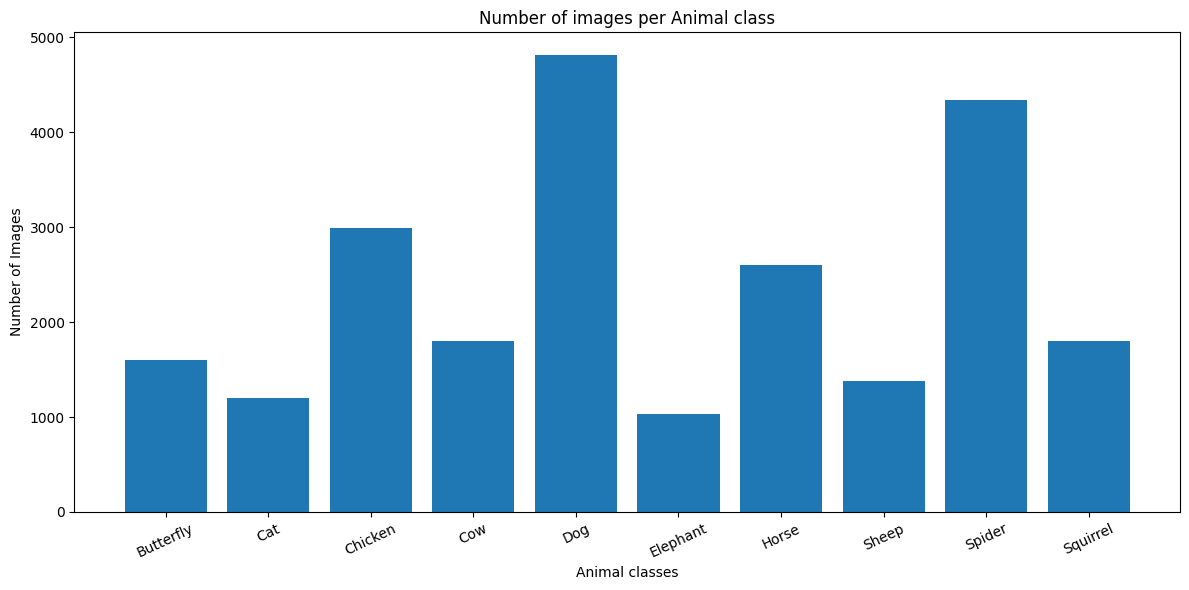

In [13]:
# @title
import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.bar(
    class_distribution["Class"],
    class_distribution["Images"]
)
plt.title("Number of images per Animal class")
plt.xlabel("Animal classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### 4.4 Class Distribution Analysis

The dataset has an imbalanced class distribution.

- **Largest Class:** Dog (4,811 images — 20.43%).
- **Smallest Class:** Elephant (1,037 images — 4.40%).
- Dog has approximately 4.6 times more images than Elephant.

This imbalance may affect the model's ability to learn all classes equally. Therefore, class distribution should be considered during model training and evaluation.